# Single window analysis

Change the settings and **Run All**. Code lives next to this notebook:

| file | what |
|---|---|
| `window.py` | load data, rule check per candle, trades in the window |
| `chart.py` | the plotly figure |
| `tables.py` | styled tables |
| `theme.py` | design: colors, EMA list, zone colors, layout |

**EMA test (`EMA_SET`):** `'9_21_200'` uses EMA 9/21/200, `'13_48_200'` uses EMA 13/48/200 - never both at the same time.

**Momentum (docs/ema.md, 15m):** fast > middle > 200 = BULL · 200 > middle > fast = BEAR · middle EMA (21 or 48) flat (moved < 0.25 ATR in 2h) or not in the middle = NONE

**Entry (docs/entry.md):** on each completed 5m candle → **BULL = BUY**, **BEAR = SELL**, **NONE = no entry**.
**BLOCKED** if the close is on the wrong side of the fast EMA (EMA9 or EMA13): distance (close − fast EMA) / ATR 5m negative for a buy, positive for a sell. Enter at the next candle's open.

**Stop loss (docs/stop_loss.md):** `STOP_LOSS` initial stop · once the trade reaches +`TRAIL_STEP` the stop follows the best price `TRAIL_GAP` behind (never moves back) · `TAKE_PROFIT` exit. All position %, price % = value / `LEVERAGE`.

`OVERLAP = True`: every momentum candle opens its own trade (many trades per window).
`OVERLAP = False`: one trade at a time, signals while in a trade are skipped.

Zones are drawn on the chart as information only - they do not filter the entry.

In [41]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, '..')              # project root: stop_loss.py, zone_create.py, data/

from analysis.window import build_window
from analysis import tables, chart

# ---------------- settings ----------------
SYMBOL      = 'BTCUSDT'
START       = '2024-12-05 00:55'      # first candle (UTC)
CANDLES     = (1, 30)                # candle range from START: (30, 60) = candle 30 to 59 | or a number, e.g. 30
LEVERAGE    = 10                      # price % = position % / LEVERAGE
STOP_LOSS   = 0.10                    # initial stop, position % (0.10 = -10% -> 10x: -1% price)
TRAIL_STEP  = 0.10                    # trail starts once the trade reaches +TRAIL_STEP
TRAIL_GAP   = None                    # stop follows the best price this far behind (None = TRAIL_STEP); 0.05 locks more profit
TAKE_PROFIT = 0.50                    # exit at +50% position (10x -> +5% price)
MARGIN_USDT = 100                     # $ per trade for P&L
EMA_SET     = '13_48_200'              # '9_21_200' or '13_48_200' (never both)
SLOPE_MIN   = 0.05                     # EMA13 (fast EMA) slope must be > this, ATR units (BUY > +min, SELL < -min); e.g. 0.05
OVERLAP     = True                    # True: trade every momentum candle | False: one trade at a time
HIGHLIGHT   = 1                       # trade # drawn with full stop / TP detail (None = none)
SHOW_ZONES  = ['15m', '1h']           # add '4h', '1d'
ZOOM        = True                    # True: y-axis fits candles + fast EMA (see EMA slope) | False: show EMA200 + stop/TP too
# ------------------------------------------

win = build_window(SYMBOL, START, CANDLES, LEVERAGE, OVERLAP, EMA_SET,
                   stop_loss=STOP_LOSS, trail_step=TRAIL_STEP, take_profit=TAKE_PROFIT, trail_gap=TRAIL_GAP, slope_min=SLOPE_MIN)
print(f"{SYMBOL}: {win.w['open_time'].iloc[0]} -> {win.w['open_time'].iloc[-1]}  ({len(win.w)} candles)")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
BTCUSDT: 2024-12-05 01:00:00+00:00 -> 2024-12-05 03:20:00+00:00  (29 candles)


## 1. Rules for each candle

✔ = allow · ✘ = block

| column | ALLOW ✔ | BLOCK ✘ |
|---|---|---|
| `EMA 13>48>200` / `EMA 200>48>13` | one is ✔ → BULL / BEAR | both ✘ → NONE |
| `EMA48 not flat` | EMA48 trending | EMA48 barely moving → NONE |
| `EMA13 slope ok` | slope with the trend (BUY > `SLOPE_MIN`, SELL < −`SLOPE_MIN`) | slope against the trend |
| `distance ok` | close on trend side of EMA13 (BUY ≥ 0, SELL ≤ 0) | close on the wrong side |
| `Not touch EMA48` | candle doesn't touch EMA48 | candle touches EMA48 |

**STATE**: BUY / SELL = all allowed · BLOCKED = momentum ok but a filter failed · NO ENTRY = momentum NONE · SKIPPED = trade already open

In [42]:
tables.rules(win)

EMA test 13_48_200 | momentum: {'BULL': 29} | state: {'BLOCKED': 17, 'BUY': 12}


,time,open,high,low,close,EMA 13>48>200,EMA 200>48>13,EMA48 slope,EMA48 not flat,MOMENTUM,EMA13 slope,EMA13 slope ok,close-EMA13 (ATR),distance ok,Not touch EMA48,ENTRY,STATE
0,12-05 01:00,98296.01,98488.00,98258.62,98379.99,✔,✘,1.13,✔,BULL,-0.02,✘,0.14,✔,✔,-,BLOCKED
1,12-05 01:05,98379.99,98437.87,98000.00,98027.98,✔,✘,1.13,✔,BULL,-0.02,✘,-1.39,✘,✔,-,BLOCKED
2,12-05 01:10,98027.98,98200.00,97888.89,97963.98,✔,✘,1.13,✔,BULL,-0.02,✘,-1.62,✘,✔,-,BLOCKED
3,12-05 01:15,97963.98,98456.00,97951.61,98291.53,✔,✘,0.98,✔,BULL,-0.12,✘,-0.01,✘,✔,-,BLOCKED
4,12-05 01:20,98291.53,98407.59,98045.51,98296.01,✔,✘,0.98,✔,BULL,-0.12,✘,0.01,✔,✔,-,BLOCKED
5,12-05 01:25,98296.01,98382.86,98047.58,98382.85,✔,✘,0.98,✔,BULL,-0.12,✘,0.33,✔,✔,-,BLOCKED
6,12-05 01:30,98382.85,98611.88,98312.40,98581.50,✔,✘,0.89,✔,BULL,0.03,✘,1.01,✔,✔,-,BLOCKED
7,12-05 01:35,98581.50,98648.47,98460.00,98516.00,✔,✘,0.89,✔,BULL,0.03,✘,0.79,✔,✔,-,BLOCKED
8,12-05 01:40,98516.01,98532.02,98404.00,98487.57,✔,✘,0.89,✔,BULL,0.03,✘,0.71,✔,✔,-,BLOCKED
9,12-05 01:45,98487.58,98500.00,98301.58,98356.82,✔,✘,0.84,✔,BULL,0.06,✔,0.09,✔,✔,BUY,BUY


## 2. Trades (stop-loss rules)

In [43]:
tables.trades(win, MARGIN_USDT)

12 trades | wins 8 | losses 4 | net +65.34$ | closed inside window 8, after window 4


,side,entry_time,entry,stop_init,take_profit,trail_steps,exit_time,exit,exit_reason,bars_held,roe,P&L $
1,long,2024-12-05 01:50:00+00:00,"98,356.82","97,373.25","103,274.66",3,2024-12-05 02:50:00+00:00,"100,600.06",trail,13,+21.7%,+21.71
2,long,2024-12-05 02:35:00+00:00,"99,727.98","98,730.70","104,714.38",1,2024-12-05 02:50:00+00:00,"100,600.06",trail,4,+7.6%,+7.64
3,long,2024-12-05 02:40:00+00:00,"99,944.00","98,944.56","104,941.20",1,2024-12-05 02:50:00+00:00,"100,600.06",trail,3,+5.5%,+5.46
4,long,2024-12-05 02:45:00+00:00,"101,312.02","100,298.90","106,377.62",2,2024-12-05 03:10:00+00:00,"103,047.12",trail,6,+16.0%,+16.03
5,long,2024-12-05 02:50:00+00:00,"101,249.25","100,236.76","106,311.71",2,2024-12-05 03:10:00+00:00,"103,047.12",trail,5,+16.7%,+16.66
6,long,2024-12-05 02:55:00+00:00,"100,968.01","99,958.33","106,016.41",3,2024-12-05 03:10:00+00:00,"103,047.12",trail,4,+19.5%,+19.49
7,long,2024-12-05 03:00:00+00:00,"101,248.19","100,235.71","106,310.60",2,2024-12-05 03:10:00+00:00,"103,047.12",trail,3,+16.7%,+16.67
8,long,2024-12-05 03:05:00+00:00,"102,312.01","101,288.89","107,427.61",1,2024-12-05 03:10:00+00:00,"103,047.12",trail,2,+6.1%,+6.09
9,long,2024-12-05 03:10:00+00:00,"103,264.01","102,231.37","108,427.21",0,2024-12-05 05:40:00+00:00,"102,231.37",stop,31,-11.1%,-11.10
10,long,2024-12-05 03:15:00+00:00,"102,919.98","101,890.78","108,065.98",0,2024-12-05 05:45:00+00:00,"101,890.78",stop,31,-11.1%,-11.10


## 3. Chart

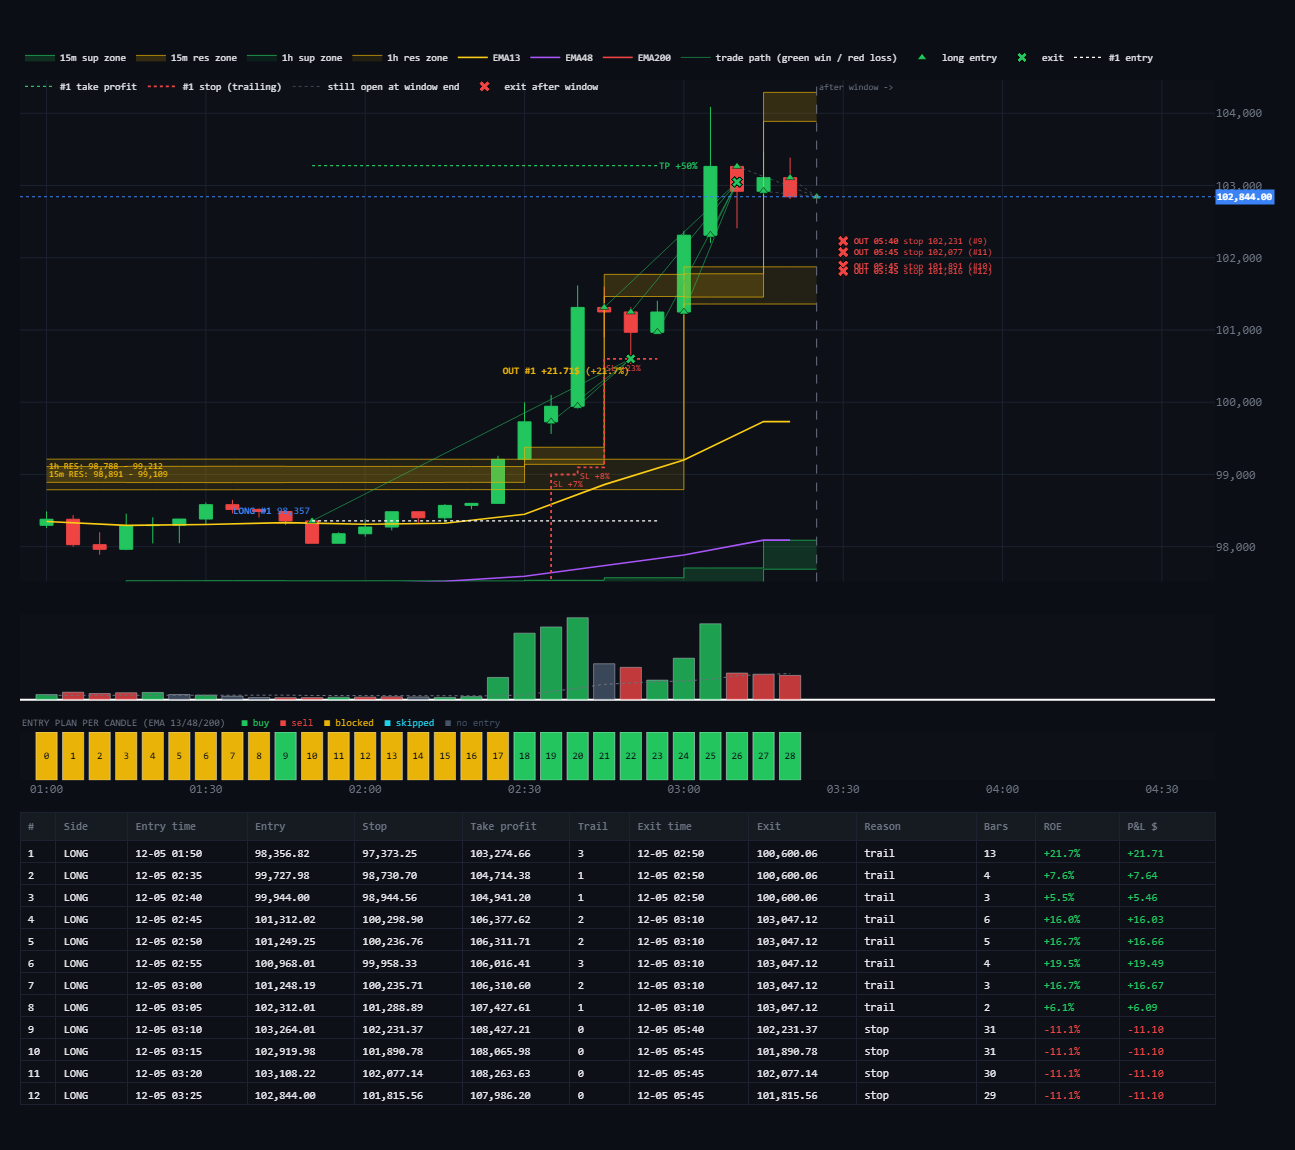

In [44]:
chart.plot_window(win, MARGIN_USDT, SHOW_ZONES, HIGHLIGHT, zoom=ZOOM).show()